In [1]:
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries loaded successfully")

C:\Users\shovo\Documents\plant_disease_thesis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries loaded successfully


In [2]:
dataset = load_dataset(
    "Project-AgML/AgriVision4_disease_classification",
    name="raw",
    split="train",
    streaming=True
)

print(dataset)

IterableDataset({
    features: ['image', 'label', 'crop'],
    num_shards: 11
})


In [3]:
print("Features:")
print(dataset.features)

print("\nNumber of shards:")
print(dataset.n_shards)

Features:
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['Alternaria_Leaf_Blight', 'Angular_Leaf_Spot', 'Anthracnose', 'Bacterial_Blight', 'Carica_Insect_Hole', 'Curled_Yellow_Spot', 'Downy_Mildew', 'Dry_Leaf', 'Early_Alternaria_Leaf_Blight', 'Fungal_Damage_Leaf', 'Healthy', 'Healthy_leaf', 'Insect_Damage', 'Iron_Chlorosis_Damage', 'Mosaic', 'Mosaic_Virus', 'Pathogen_symptoms', 'Spot', 'White_spot', 'Xanthomonas_Leaf_Spot', 'Yellow_Mosaic_Virus', 'Yellow_Necrotic_Spots_Holes']), 'crop': Value('string')}

Number of shards:
11


In [4]:
count = 0

for _ in dataset:
    count += 1

print("Total raw images:", count)

KeyboardInterrupt: 

In [5]:
print("Dataset:", dataset)
print("Number of shards:", dataset.n_shards)
print("Approximate number of rows:", dataset.info.dataset_size)

Dataset: IterableDataset({
    features: ['image', 'label', 'crop'],
    num_shards: 11
})
Number of shards: 11
Approximate number of rows: 5488515233


In [6]:
print("Dataset features:")
print(dataset.features)

print("\nDataset information:")
print(dataset.info)

print("\nNumber of shards:")
print(dataset.n_shards)

Dataset features:
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['Alternaria_Leaf_Blight', 'Angular_Leaf_Spot', 'Anthracnose', 'Bacterial_Blight', 'Carica_Insect_Hole', 'Curled_Yellow_Spot', 'Downy_Mildew', 'Dry_Leaf', 'Early_Alternaria_Leaf_Blight', 'Fungal_Damage_Leaf', 'Healthy', 'Healthy_leaf', 'Insect_Damage', 'Iron_Chlorosis_Damage', 'Mosaic', 'Mosaic_Virus', 'Pathogen_symptoms', 'Spot', 'White_spot', 'Xanthomonas_Leaf_Spot', 'Yellow_Mosaic_Virus', 'Yellow_Necrotic_Spots_Holes']), 'crop': Value('string')}

Dataset information:
DatasetInfo(features={'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['Alternaria_Leaf_Blight', 'Angular_Leaf_Spot', 'Anthracnose', 'Bacterial_Blight', 'Carica_Insect_Hole', 'Curled_Yellow_Spot', 'Downy_Mildew', 'Dry_Leaf', 'Early_Alternaria_Leaf_Blight', 'Fungal_Damage_Leaf', 'Healthy', 'Healthy_leaf', 'Insect_Damage', 'Iron_Chlorosis_Damage', 'Mosaic', 'Mosaic_Virus', 'Pathogen_symptoms', 'Spot', 'White_spot', 'Xant

In [7]:
class_names = dataset.features["label"].names

print("Number of classes:", len(class_names))
print("\nClass names:")

for i, name in enumerate(class_names, start=1):
    print(f"{i}. {name}")

Number of classes: 22

Class names:
1. Alternaria_Leaf_Blight
2. Angular_Leaf_Spot
3. Anthracnose
4. Bacterial_Blight
5. Carica_Insect_Hole
6. Curled_Yellow_Spot
7. Downy_Mildew
8. Dry_Leaf
9. Early_Alternaria_Leaf_Blight
10. Fungal_Damage_Leaf
11. Healthy
12. Healthy_leaf
13. Insect_Damage
14. Iron_Chlorosis_Damage
15. Mosaic
16. Mosaic_Virus
17. Pathogen_symptoms
18. Spot
19. White_spot
20. Xanthomonas_Leaf_Spot
21. Yellow_Mosaic_Virus
22. Yellow_Necrotic_Spots_Holes


In [9]:
from collections import Counter
from itertools import islice

sample = list(islice(dataset, 100))

label_counts = Counter(item["label"] for item in sample)

print("Number of sampled images:", len(sample))
print("\nClass distribution in the sample:")

for label_id, count in sorted(label_counts.items()):
    print(f"{class_names[label_id]}: {count}")

Number of sampled images: 100

Class distribution in the sample:
Alternaria_Leaf_Blight: 100


In [10]:
for i, item in enumerate(sample[:20], start=1):
    print(i, item["label"], class_names[item["label"]])

1 0 Alternaria_Leaf_Blight
2 0 Alternaria_Leaf_Blight
3 0 Alternaria_Leaf_Blight
4 0 Alternaria_Leaf_Blight
5 0 Alternaria_Leaf_Blight
6 0 Alternaria_Leaf_Blight
7 0 Alternaria_Leaf_Blight
8 0 Alternaria_Leaf_Blight
9 0 Alternaria_Leaf_Blight
10 0 Alternaria_Leaf_Blight
11 0 Alternaria_Leaf_Blight
12 0 Alternaria_Leaf_Blight
13 0 Alternaria_Leaf_Blight
14 0 Alternaria_Leaf_Blight
15 0 Alternaria_Leaf_Blight
16 0 Alternaria_Leaf_Blight
17 0 Alternaria_Leaf_Blight
18 0 Alternaria_Leaf_Blight
19 0 Alternaria_Leaf_Blight
20 0 Alternaria_Leaf_Blight


In [11]:
print(type(dataset))
print("\nDataset features:", dataset.features)
print("\nAvailable methods:")
print([name for name in dir(dataset) if "count" in name or "shard" in name])

<class 'datasets.iterable_dataset.IterableDataset'>

Dataset features: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['Alternaria_Leaf_Blight', 'Angular_Leaf_Spot', 'Anthracnose', 'Bacterial_Blight', 'Carica_Insect_Hole', 'Curled_Yellow_Spot', 'Downy_Mildew', 'Dry_Leaf', 'Early_Alternaria_Leaf_Blight', 'Fungal_Damage_Leaf', 'Healthy', 'Healthy_leaf', 'Insect_Damage', 'Iron_Chlorosis_Damage', 'Mosaic', 'Mosaic_Virus', 'Pathogen_symptoms', 'Spot', 'White_spot', 'Xanthomonas_Leaf_Spot', 'Yellow_Mosaic_Virus', 'Yellow_Necrotic_Spots_Holes']), 'crop': Value('string')}

Available methods:
['_push_parquet_shards_to_hub', '_push_parquet_shards_to_hub_single', '_write_parquet_shards', 'n_shards', 'num_shards', 'reshard', 'shard']


In [12]:
import importlib.util

print("PyArrow available:", importlib.util.find_spec("pyarrow") is not None)
print("fsspec available:", importlib.util.find_spec("fsspec") is not None)

PyArrow available: True
fsspec available: True


In [13]:
print("Dataset cache files:")
print(dataset.cache_files)

Dataset cache files:


AttributeError: 'IterableDataset' object has no attribute 'cache_files'

In [14]:
import datasets

print("Hugging Face datasets version:", datasets.__version__)

Hugging Face datasets version: 5.1.0


In [15]:
from pathlib import Path

data_path = Path(r"F:\Thesis\Original_Dataset\Original_Dataset")

print("Folder exists:", data_path.exists())

if data_path.exists():
    print("\nFolders found:")
    for folder in data_path.iterdir():
        if folder.is_dir():
            print("-", folder.name)
else:
    print("Please check the dataset folder path.")

Folder exists: False
Please check the dataset folder path.


In [16]:
from pathlib import Path

data_path = Path(r"F:\Thesis\Orginal_Dataset")

print("Folder exists:", data_path.exists())

if data_path.exists():
    print("\nFolders found:")
    for folder in data_path.iterdir():
        if folder.is_dir():
            print("-", folder.name)

Folder exists: True

Folders found:
- Orginal_Dataset


In [17]:
from pathlib import Path

image_root = data_path / "Orginal_Dataset"

print("Image folder exists:", image_root.exists())

if image_root.exists():
    print("\nCrop folders:")
    for folder in sorted(image_root.iterdir()):
        if folder.is_dir():
            print("-", folder.name)

Image folder exists: True

Crop folders:
- Batol_Gourd
- papaya_main_dataset
- Tomato
- Zucchini_Original


In [18]:
for crop_folder in sorted(image_root.iterdir()):
    if crop_folder.is_dir():
        print(f"\n{crop_folder.name}:")
        for class_folder in sorted(crop_folder.iterdir()):
            if class_folder.is_dir():
                print("  -", class_folder.name)


Batol_Gourd:
  - Alternaria_Leaf_Blight
  - Anthracnose
  - Downy_Mildew
  - Early_Alternaria_Leaf_Blight
  - Fungal_Damage_Leaf
  - Healthy
  - Mosaic_Virus

papaya_main_dataset:
  - Bacterial_Blight
  - Carica_Insect_Hole
  - Curled_Yellow_Spot
  - healthy_leaf
  - Mosaic_Virus
  - pathogen_symptoms
  - Yellow_Necrotic_Spots_Holes

Tomato:
  - Downy Mildew
  - Healthy
  - Mosaic
  - Spot
  - white_spot

Zucchini_Original:
  - Angular_Leaf_Spot
  - Anthracnose
  - Downy_Midew
  - Dry_Leaf
  - Healthy
  - Insect_Damage
  - Iron_Chlorosis_Damage
  - Xanthomonas_Leaf_Spot
  - Yellow_Mosaic_Virus


In [19]:
from collections import Counter

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

class_counts = []

for crop_folder in sorted(image_root.iterdir()):
    if not crop_folder.is_dir():
        continue

    for class_folder in sorted(crop_folder.iterdir()):
        if not class_folder.is_dir():
            continue

        count = sum(
            1 for file in class_folder.rglob("*")
            if file.is_file() and file.suffix.lower() in image_extensions
        )

        class_counts.append({
            "crop": crop_folder.name,
            "class": class_folder.name,
            "images": count
        })

print("Number of classes:", len(class_counts))
print("Total images:", sum(item["images"] for item in class_counts))

for item in class_counts:
    print(f"{item['crop']} | {item['class']} | {item['images']}")

Number of classes: 28
Total images: 5246
Batol_Gourd | Alternaria_Leaf_Blight | 303
Batol_Gourd | Anthracnose | 276
Batol_Gourd | Downy_Mildew | 286
Batol_Gourd | Early_Alternaria_Leaf_Blight | 179
Batol_Gourd | Fungal_Damage_Leaf | 39
Batol_Gourd | Healthy | 260
Batol_Gourd | Mosaic_Virus | 315
papaya_main_dataset | Bacterial_Blight | 183
papaya_main_dataset | Carica_Insect_Hole | 318
papaya_main_dataset | Curled_Yellow_Spot | 538
papaya_main_dataset | healthy_leaf | 189
papaya_main_dataset | Mosaic_Virus | 119
papaya_main_dataset | pathogen_symptoms | 286
papaya_main_dataset | Yellow_Necrotic_Spots_Holes | 51
Tomato | Downy Mildew | 57
Tomato | Healthy | 288
Tomato | Mosaic | 195
Tomato | Spot | 311
Tomato | white_spot | 65
Zucchini_Original | Angular_Leaf_Spot | 120
Zucchini_Original | Anthracnose | 129
Zucchini_Original | Downy_Midew | 153
Zucchini_Original | Dry_Leaf | 67
Zucchini_Original | Healthy | 88
Zucchini_Original | Insect_Damage | 78
Zucchini_Original | Iron_Chlorosis_Dam

In [20]:
print("Total images:", sum(item["images"] for item in class_counts))

print("\nClasses with fewer than 100 images:")
for item in class_counts:
    if item["images"] < 100:
        print(f"{item['crop']} | {item['class']} | {item['images']}")

Total images: 5246

Classes with fewer than 100 images:
Batol_Gourd | Fungal_Damage_Leaf | 39
papaya_main_dataset | Yellow_Necrotic_Spots_Holes | 51
Tomato | Downy Mildew | 57
Tomato | white_spot | 65
Zucchini_Original | Dry_Leaf | 67
Zucchini_Original | Healthy | 88
Zucchini_Original | Insect_Damage | 78
Zucchini_Original | Iron_Chlorosis_Damage | 65
Zucchini_Original | Xanthomonas_Leaf_Spot | 86


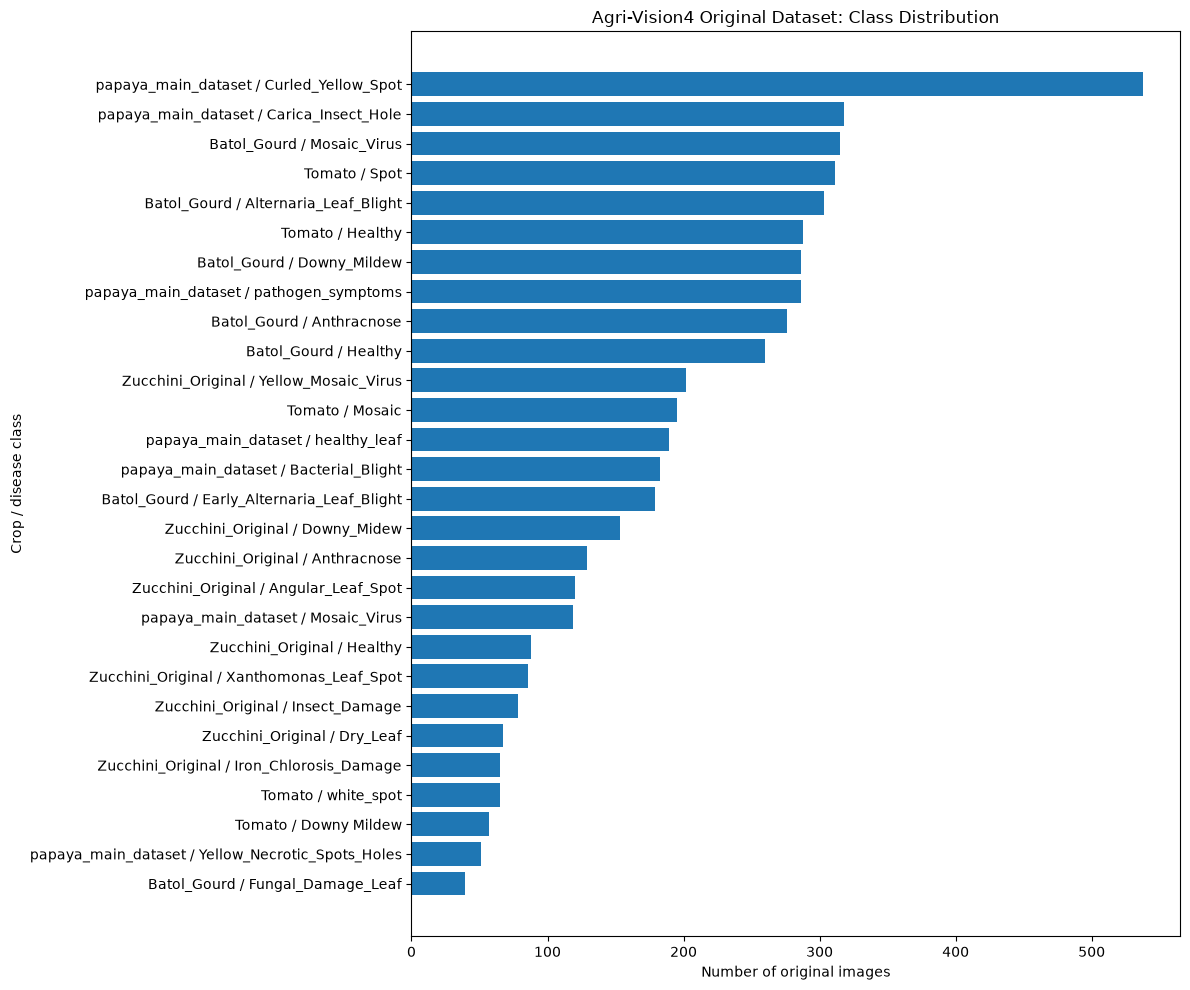

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

counts_df = pd.DataFrame(class_counts)
counts_df["crop_class"] = (
    counts_df["crop"] + " / " + counts_df["class"]
)

counts_df = counts_df.sort_values("images")

plt.figure(figsize=(12, 10))
plt.barh(counts_df["crop_class"], counts_df["images"])
plt.xlabel("Number of original images")
plt.ylabel("Crop / disease class")
plt.title("Agri-Vision4 Original Dataset: Class Distribution")
plt.tight_layout()
plt.show()

In [22]:
output_path = data_path / "agrivision4_original_class_counts.csv"

counts_df[["crop", "class", "images"]].to_csv(
    output_path,
    index=False
)

print("Saved to:", output_path)
print("Rows saved:", len(counts_df))

Saved to: F:\Thesis\Orginal_Dataset\agrivision4_original_class_counts.csv
Rows saved: 28


In [23]:
print("DATASET SUMMARY")
print("-" * 40)
print("Number of classes:", len(counts_df))
print("Total images:", counts_df["images"].sum())
print("Average images per class:", round(counts_df["images"].mean(), 2))
print("Median images per class:", counts_df["images"].median())

largest = counts_df.loc[counts_df["images"].idxmax()]
smallest = counts_df.loc[counts_df["images"].idxmin()]

print("\nLargest class:")
print(largest["crop"], "|", largest["class"], "|", largest["images"])

print("\nSmallest class:")
print(smallest["crop"], "|", smallest["class"], "|", smallest["images"])

print("\nREADME total: 5266")
print("Difference:", 5266 - counts_df["images"].sum())

DATASET SUMMARY
----------------------------------------
Number of classes: 28
Total images: 5246
Average images per class: 187.36
Median images per class: 181.0

Largest class:
papaya_main_dataset | Curled_Yellow_Spot | 538

Smallest class:
Batol_Gourd | Fungal_Damage_Leaf | 39

README total: 5266
Difference: 20


In [24]:
report_path = data_path / "agrivision4_verification_report.txt"

report = f"""Agri-Vision4 Original Dataset Verification
Date: 2026-10-12

Source: Mendeley Data, Original_Dataset.zip
Image root: {image_root}

Classes found: {len(counts_df)}
Images counted: {counts_df["images"].sum()}
README expected images: 5266
Difference: {5266 - counts_df["images"].sum()}

Average images per class: {counts_df["images"].mean():.2f}
Median images per class: {counts_df["images"].median():.2f}

Largest class:
{largest["crop"]} / {largest["class"]}: {largest["images"]}

Smallest class:
{smallest["crop"]} / {smallest["class"]}: {smallest["images"]}

Known discrepancy:
Zucchini / Healthy contains 88 images in the extracted files,
while the README lists 108.

These counts describe the extracted files and should be
rechecked before final experimental dataset preparation.
"""

report_path.write_text(report, encoding="utf-8")
print("Report saved to:", report_path)

Report saved to: F:\Thesis\Orginal_Dataset\agrivision4_verification_report.txt


In [25]:
from PIL import Image

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

sample_files = [
    file
    for file in image_root.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
][:20]

print("Images selected for testing:", len(sample_files))

readable = 0
unreadable = []

for file in sample_files:
    try:
        with Image.open(file) as img:
            img.verify()
        readable += 1
    except Exception as e:
        unreadable.append((str(file), str(e)))

print("Readable images:", readable)
print("Unreadable images:", len(unreadable))

for file, error in unreadable:
    print(file, "|", error)

Images selected for testing: 20
Readable images: 20
Unreadable images: 0


In [26]:
from PIL import Image
from tqdm.auto import tqdm

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

all_image_files = [
    file for file in image_root.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
]

unreadable_images = []

for file in tqdm(all_image_files, desc="Checking image integrity"):
    try:
        with Image.open(file) as img:
            img.verify()
    except Exception as e:
        unreadable_images.append((str(file), str(e)))

print("\nTotal image files checked:", len(all_image_files))
print("Unreadable images:", len(unreadable_images))

for file, error in unreadable_images[:20]:
    print(file, "|", error)

Checking image integrity: 100%|██████████| 5246/5246 [00:55<00:00, 93.77it/s] 


Total image files checked: 5246
Unreadable images: 0


In [27]:
import hashlib
from collections import defaultdict
from tqdm.auto import tqdm

hash_to_files = defaultdict(list)

for file in tqdm(all_image_files, desc="Checking exact duplicates"):
    sha256 = hashlib.sha256()

    with open(file, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    hash_to_files[sha256.hexdigest()].append(str(file))

duplicate_groups = [
    files for files in hash_to_files.values()
    if len(files) > 1
]

duplicate_file_count = sum(
    len(files) for files in duplicate_groups
)

print("Total files checked:", len(all_image_files))
print("Unique file contents:", len(hash_to_files))
print("Duplicate groups:", len(duplicate_groups))
print("Files belonging to duplicate groups:", duplicate_file_count)

for group in duplicate_groups[:10]:
    print("\nDuplicate group:")
    for file in group:
        print(" -", file)

Checking exact duplicates: 100%|██████████| 5246/5246 [00:10<00:00, 508.08it/s]

Total files checked: 5246
Unique file contents: 4304
Duplicate groups: 618
Files belonging to duplicate groups: 1560

Duplicate group:
 - F:\Thesis\Orginal_Dataset\Orginal_Dataset\Zucchini_Original\Angular_Leaf_Spot\1730294736960.png
 - F:\Thesis\Orginal_Dataset\Orginal_Dataset\Zucchini_Original\Anthracnose\1730294736960.png
 - F:\Thesis\Orginal_Dataset\Orginal_Dataset\Zucchini_Original\Downy_Midew\1730294736960.png

Duplicate group:
 - F:\Thesis\Orginal_Dataset\Orginal_Dataset\Zucchini_Original\Angular_Leaf_Spot\1730294736975.png
 - F:\Thesis\Orginal_Dataset\Orginal_Dataset\Zucchini_Original\Downy_Midew\1730294736975.png
 - F:\Thesis\Orginal_Dataset\Orginal_Dataset\Zucchini_Original\Iron_Chlorosis_Damage\1730294736975.png

Duplicate group:
 - F:\Thesis\Orginal_Dataset\Orginal_Dataset\Zucchini_Original\Angular_Leaf_Spot\1730294736992 - Copy.png
 - F:\Thesis\Orginal_Dataset\Orginal_Dataset\Zucchini_Original\Anthracnose\1730294736992.png
 - F:\Thesis\Orginal_Dataset\Orginal_Dataset\Zucch

In [28]:
from pathlib import Path
from collections import defaultdict

duplicate_groups_by_class = defaultdict(list)

for files in hash_to_files.values():
    if len(files) > 1:
        classes = {
            Path(file).parent.name
            for file in files
        }

        duplicate_groups_by_class[len(classes)].append(files)

cross_class_groups = [
    files
    for number_of_classes, groups in duplicate_groups_by_class.items()
    if number_of_classes > 1
    for files in groups
]

print("Duplicate groups spanning multiple class folders:",
      len(cross_class_groups))

for group in cross_class_groups[:5]:
    print("\nGroup:")
    for file in group:
        print(" -", file)

Duplicate groups spanning multiple class folders: 275

Group:
 - F:\Thesis\Orginal_Dataset\Orginal_Dataset\Zucchini_Original\Angular_Leaf_Spot\1730294736960.png
 - F:\Thesis\Orginal_Dataset\Orginal_Dataset\Zucchini_Original\Anthracnose\1730294736960.png
 - F:\Thesis\Orginal_Dataset\Orginal_Dataset\Zucchini_Original\Downy_Midew\1730294736960.png

Group:
 - F:\Thesis\Orginal_Dataset\Orginal_Dataset\Zucchini_Original\Angular_Leaf_Spot\1730294736975.png
 - F:\Thesis\Orginal_Dataset\Orginal_Dataset\Zucchini_Original\Downy_Midew\1730294736975.png
 - F:\Thesis\Orginal_Dataset\Orginal_Dataset\Zucchini_Original\Iron_Chlorosis_Damage\1730294736975.png

Group:
 - F:\Thesis\Orginal_Dataset\Orginal_Dataset\Zucchini_Original\Angular_Leaf_Spot\1730294736992 - Copy.png
 - F:\Thesis\Orginal_Dataset\Orginal_Dataset\Zucchini_Original\Anthracnose\1730294736992.png
 - F:\Thesis\Orginal_Dataset\Orginal_Dataset\Zucchini_Original\Downy_Midew\1730294736992.png

Group:
 - F:\Thesis\Orginal_Dataset\Orginal_Datas

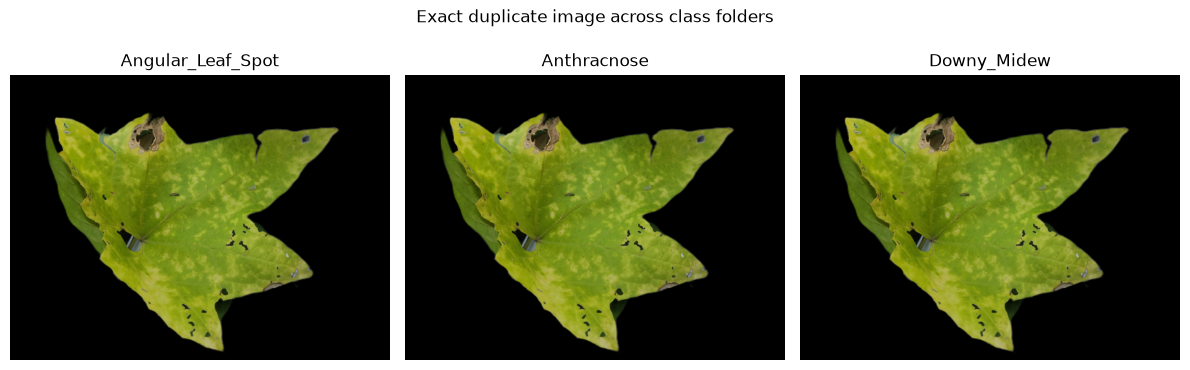

In [29]:
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

example_group = cross_class_groups[0]

fig, axes = plt.subplots(1, len(example_group), figsize=(12, 4))

for ax, file in zip(axes, example_group):
    with Image.open(file) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(Path(file).parent.name)
    ax.axis("off")

plt.suptitle("Exact duplicate image across class folders")
plt.tight_layout()
plt.show()

In [30]:
duplicate_report_path = data_path / "agrivision4_duplicate_report.txt"

report = f"""Agri-Vision4 Exact Duplicate Analysis
Date: 2026-10-12

Total image files: {len(all_image_files)}
Unique file contents: {len(hash_to_files)}
Duplicate groups: {len(duplicate_groups)}
Files belonging to duplicate groups: {duplicate_file_count}
Duplicate groups spanning multiple class folders: {len(cross_class_groups)}

Method:
SHA-256 hashes were calculated from file contents.
Files with identical hashes were grouped together.

Important limitation:
Exact duplicates across class folders indicate a potential label-quality
issue. The correct disease labels have not been independently verified.
No images have been deleted or relabeled.
"""

duplicate_report_path.write_text(report, encoding="utf-8")
print("Duplicate report saved to:", duplicate_report_path)

Duplicate report saved to: F:\Thesis\Orginal_Dataset\agrivision4_duplicate_report.txt


In [31]:
from pathlib import Path
from collections import Counter

crop_duplicate_groups = Counter()

for group in cross_class_groups:
    crops = {
        Path(file).parent.parent.name
        for file in group
    }

    for crop in crops:
        crop_duplicate_groups[crop] += 1

print("Cross-class duplicate groups by crop:")
for crop, count in crop_duplicate_groups.most_common():
    print(f"{crop}: {count}")

Cross-class duplicate groups by crop:
Zucchini_Original: 245
papaya_main_dataset: 18
Tomato: 9
Batol_Gourd: 3


In [32]:
from pathlib import Path

print("Crop-level image summary")
print("-" * 55)

for crop_folder in sorted(image_root.iterdir()):
    if not crop_folder.is_dir():
        continue

    crop_files = [
        file for file in crop_folder.rglob("*")
        if file.is_file() and file.suffix.lower() in image_extensions
    ]

    crop_hashes = set()

    for file in crop_files:
        sha256 = hashlib.sha256()
        with open(file, "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                sha256.update(chunk)
        crop_hashes.add(sha256.hexdigest())

    print(
        f"{crop_folder.name}: "
        f"{len(crop_files)} files, "
        f"{len(crop_hashes)} unique file contents"
    )

Crop-level image summary
-------------------------------------------------------
Batol_Gourd: 1658 files, 1494 unique file contents
papaya_main_dataset: 1684 files, 1485 unique file contents
Tomato: 916 files, 804 unique file contents
Zucchini_Original: 988 files, 521 unique file contents


In [33]:
from collections import defaultdict
from pathlib import Path

same_class_groups = 0
cross_class_groups = 0

for files in hash_to_files.values():
    if len(files) < 2:
        continue

    class_names = {Path(file).parent.name for file in files}

    if len(class_names) == 1:
        same_class_groups += 1
    else:
        cross_class_groups += 1

print("Duplicate groups within one class:", same_class_groups)
print("Duplicate groups across multiple classes:", cross_class_groups)

Duplicate groups within one class: 343
Duplicate groups across multiple classes: 275


In [34]:
with open(duplicate_report_path, "a", encoding="utf-8") as f:
    f.write(f"""
Duplicate group breakdown
-------------------------
Within one class: {same_class_groups}
Across multiple classes: {cross_class_groups}

Crop-level summary
------------------
""")

    for crop_folder in sorted(image_root.iterdir()):
        if not crop_folder.is_dir():
            continue

        crop_files = [
            file for file in crop_folder.rglob("*")
            if file.is_file() and file.suffix.lower() in image_extensions
        ]

        f.write(f"{crop_folder.name}: {len(crop_files)} image files\\n")

print("Updated report:", duplicate_report_path)

Updated report: F:\Thesis\Orginal_Dataset\agrivision4_duplicate_report.txt


In [35]:
print("Image files:", len(all_image_files))
print("Hash groups:", len(hash_to_files))
print("Duplicate groups:", len(duplicate_groups))
print("Cross-class duplicate groups:", len(cross_class_groups))

Image files: 5246
Hash groups: 4304
Duplicate groups: 618


TypeError: object of type 'int' has no len()

In [36]:
print("Image files:", len(all_image_files))
print("Unique file contents:", len(hash_to_files))
print("Duplicate groups:", len(duplicate_groups))
print("Cross-class duplicate groups:", cross_class_groups)

Image files: 5246
Unique file contents: 4304
Duplicate groups: 618
Cross-class duplicate groups: 275


In [37]:
from pathlib import Path
import pandas as pd

review_rows = []

for files in hash_to_files.values():
    if len(files) < 2:
        continue

    labels = sorted({Path(file).parent.name for file in files})

    review_rows.append({
        "copies": len(files),
        "label_count": len(labels),
        "labels": " | ".join(labels),
        "files": " | ".join(str(file) for file in files)
    })

review_df = pd.DataFrame(review_rows)

review_path = data_path / "agrivision4_duplicate_review.csv"
review_df.to_csv(review_path, index=False)

print("Duplicate groups:", len(review_df))
print("Within-class groups:", (review_df["label_count"] == 1).sum())
print("Cross-class groups:", (review_df["label_count"] > 1).sum())
print("Saved review table:", review_path)

Duplicate groups: 618
Within-class groups: 343
Cross-class groups: 275
Saved review table: F:\Thesis\Orginal_Dataset\agrivision4_duplicate_review.csv


In [38]:
from pathlib import Path
import hashlib
import pandas as pd

# Map each image to its SHA-256 hash and class label
rows = []

for file in all_image_files:
    sha256 = hashlib.sha256()
    with open(file, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    rows.append({
        "path": str(file),
        "crop": file.parent.parent.name,
        "class": file.parent.name,
        "sha256": sha256.hexdigest()
    })

manifest = pd.DataFrame(rows)

# Determine whether each hash occurs in one or multiple classes
labels_per_hash = manifest.groupby("sha256")["class"].nunique()
copies_per_hash = manifest.groupby("sha256")["path"].count()

manifest["copies_with_same_hash"] = manifest["sha256"].map(copies_per_hash)
manifest["labels_for_hash"] = manifest["sha256"].map(labels_per_hash)

manifest["status"] = "KEEP"

manifest.loc[
    (manifest["copies_with_same_hash"] > 1) &
    (manifest["labels_for_hash"] == 1),
    "status"
] = "KEEP_ONE_COPY"

manifest.loc[
    manifest["labels_for_hash"] > 1,
    "status"
] = "REVIEW_CONFLICT"

manifest_path = data_path / "agrivision4_cleaning_manifest.csv"
manifest.to_csv(manifest_path, index=False)

print("Images listed:", len(manifest))
print("\nStatus counts:")
print(manifest["status"].value_counts())
print("\nManifest saved to:", manifest_path)

Images listed: 5246

Status counts:
status
KEEP               3686
KEEP_ONE_COPY       806
REVIEW_CONFLICT     754
Name: count, dtype: int64

Manifest saved to: F:\Thesis\Orginal_Dataset\agrivision4_cleaning_manifest.csv


In [39]:

# Check how many images remain under our proposed cleaning rule.
# This is only a preview; no files will be changed.

safe_df = manifest[manifest["status"] != "REVIEW_CONFLICT"].copy()

print("Original images:", len(manifest))
print("Images excluded for conflicting labels:",
      (manifest["status"] == "REVIEW_CONFLICT").sum())
print("Images remaining before removing same-class copies:",
      len(safe_df))

print("\nImages per class after excluding conflicts:")
print(
    safe_df.groupby(["crop", "class"])["path"]
    .count()
    .sort_values()
    .to_string()
)


Original images: 5246
Images excluded for conflicting labels: 754
Images remaining before removing same-class copies: 4492

Images per class after excluding conflicts:
crop                 class                       
Zucchini_Original    Iron_Chlorosis_Damage             1
                     Xanthomonas_Leaf_Spot             3
                     Dry_Leaf                          5
                     Angular_Leaf_Spot                10
                     Insect_Damage                    10
                     Healthy                          13
                     Downy_Midew                      30
Batol_Gourd          Fungal_Damage_Leaf               39
Zucchini_Original    Anthracnose                      46
papaya_main_dataset  Yellow_Necrotic_Spots_Holes      51
Tomato               Downy Mildew                     56
                     white_spot                       65
papaya_main_dataset  Mosaic_Virus                    105
                     Bacterial_Blight    

In [40]:
# Count unique image contents within each crop/class folder.
# This only calculates counts; it does not change any files.

unique_counts = (
    manifest.drop_duplicates(subset=["class", "sha256"])
    .groupby(["crop", "class"])
    .size()
    .sort_values()
)

print("Unique images per class:")
print(unique_counts.to_string())

Unique images per class:
crop                 class                       
Batol_Gourd          Fungal_Damage_Leaf               38
papaya_main_dataset  Yellow_Necrotic_Spots_Holes      50
Tomato               Downy Mildew                     56
Zucchini_Original    Dry_Leaf                         61
                     Xanthomonas_Leaf_Spot            61
                     Iron_Chlorosis_Damage            62
                     Healthy                          64
Tomato               white_spot                       65
Zucchini_Original    Insect_Damage                    68
papaya_main_dataset  Mosaic_Virus                    102
Zucchini_Original    Angular_Leaf_Spot               111
                     Anthracnose                     122
                     Downy_Midew                     130
papaya_main_dataset  Bacterial_Blight                145
Batol_Gourd          Early_Alternaria_Leaf_Blight    159
Zucchini_Original    Yellow_Mosaic_Virus             176
papaya_main_d

In [41]:

# Prepare a file list for all four crops.
# This does not modify or delete any images.

experiment_df = manifest[
    ["path", "crop", "class", "sha256"]
].copy()

# Create a unique label for each crop-disease combination.
experiment_df["label"] = (
    experiment_df["crop"].astype(str)
    + " / "
    + experiment_df["class"].astype(str)
)

experiment_path = data_path / "agrivision4_experiment_file_list.csv"
experiment_df.to_csv(experiment_path, index=False)

print("Total image records:", len(experiment_df))
print("Number of crop-disease classes:", experiment_df["label"].nunique())
print("\nImages per crop:")
print(experiment_df.groupby("crop").size().to_string())
print("\nFile list saved to:", experiment_path)


Total image records: 5246
Number of crop-disease classes: 28

Images per crop:
crop
Batol_Gourd            1658
Tomato                  916
Zucchini_Original       988
papaya_main_dataset    1684

File list saved to: F:\Thesis\Orginal_Dataset\agrivision4_experiment_file_list.csv


In [42]:

from sklearn.model_selection import StratifiedGroupKFold
import numpy as np

# Use the existing experiment file list.
df = experiment_df.copy().reset_index(drop=True)

# First, reserve approximately 15% for testing.
splitter_test = StratifiedGroupKFold(
    n_splits=7, shuffle=True, random_state=42
)

trainval_idx, test_idx = next(
    (train_idx, test_idx)
    for train_idx, test_idx in splitter_test.split(
        df, y=df["label"], groups=df["sha256"]
    )
)

# Divide the remaining data into training and validation.
trainval = df.iloc[trainval_idx].reset_index(drop=True)

splitter_val = StratifiedGroupKFold(
    n_splits=6, shuffle=True, random_state=42
)

train_idx, val_idx = next(
    splitter_val.split(
        trainval, y=trainval["label"], groups=trainval["sha256"]
    )
)

df["split"] = "test"
df.loc[trainval_idx, "split"] = "validation"
df.loc[trainval_idx[train_idx], "split"] = "train"

print("Split sizes:")
print(df["split"].value_counts())
print("\nNumber of classes per split:")
print(df.groupby("split")["label"].nunique())


Split sizes:
split
train         3746
test           750
validation     750
Name: count, dtype: int64

Number of classes per split:
split
test          28
train         28
validation    28
Name: label, dtype: int64


In [43]:

# Check whether identical image contents cross split boundaries.
hash_split_counts = df.groupby("sha256")["split"].nunique()

leaking_hashes = hash_split_counts[hash_split_counts > 1]

print("Hashes appearing in multiple splits:", len(leaking_hashes))

if len(leaking_hashes) == 0:
    print("PASS: No exact-duplicate leakage between splits.")
else:
    print("WARNING: Duplicate leakage detected. Do not save these splits yet.")


Hashes appearing in multiple splits: 0
PASS: No exact-duplicate leakage between splits.


In [44]:

# Save the reproducible train/validation/test assignments
split_path = data_path / "agrivision4_splits.csv"

df.to_csv(split_path, index=False)

print("Split file saved to:", split_path)
print("\nFinal split sizes:")
print(df["split"].value_counts())

print("\nClass counts by split:")
print(pd.crosstab(df["label"], df["split"]).to_string())


Split file saved to: F:\Thesis\Orginal_Dataset\agrivision4_splits.csv

Final split sizes:
split
train         3746
test           750
validation     750
Name: count, dtype: int64

Class counts by split:
split                                              test  train  validation
label                                                                     
Batol_Gourd / Alternaria_Leaf_Blight                 44    216          43
Batol_Gourd / Anthracnose                            39    197          40
Batol_Gourd / Downy_Mildew                           41    204          41
Batol_Gourd / Early_Alternaria_Leaf_Blight           26    127          26
Batol_Gourd / Fungal_Damage_Leaf                      5     29           5
Batol_Gourd / Healthy                                38    185          37
Batol_Gourd / Mosaic_Virus                           45    225          45
Tomato / Downy Mildew                                 9     40           8
Tomato / Healthy                               

In [45]:

from pathlib import Path
import pandas as pd

split_path = data_path / "agrivision4_splits.csv"

print("Split file exists:", split_path.exists())

saved_df = pd.read_csv(split_path)

print("Total records:", len(saved_df))
print("Number of classes:", saved_df["label"].nunique())
print("\nSplit sizes:")
print(saved_df["split"].value_counts())


Split file exists: True
Total records: 5246
Number of classes: 28

Split sizes:
split
train         3746
test           750
validation     750
Name: count, dtype: int64


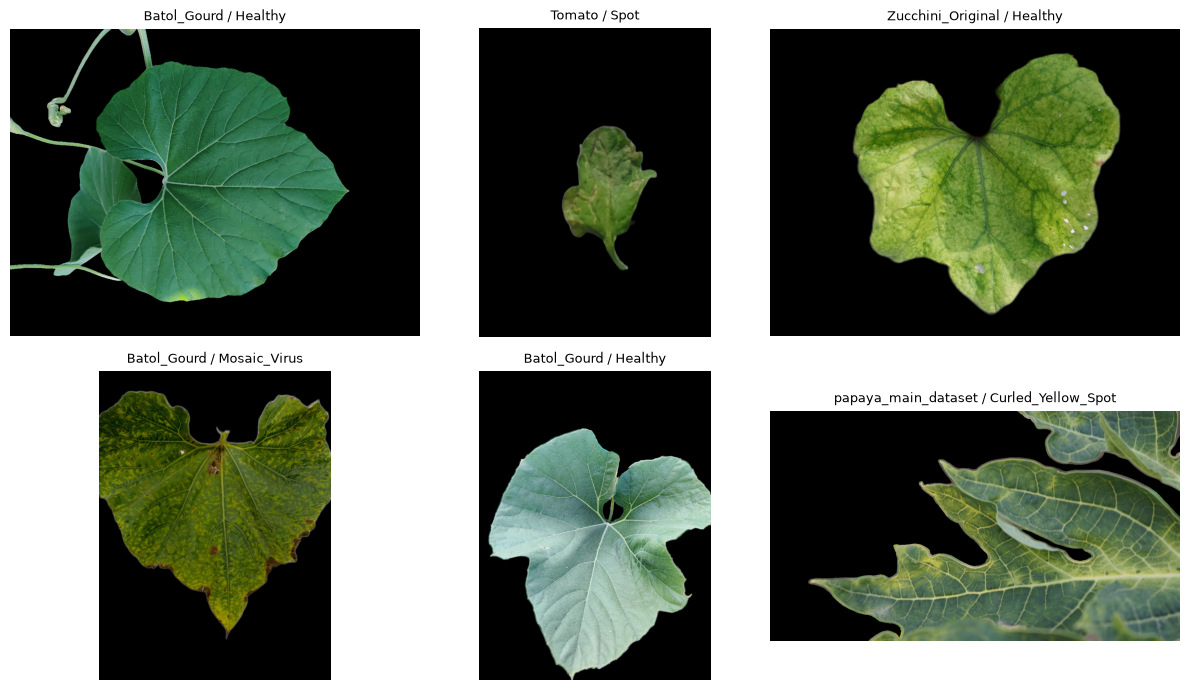

In [46]:

import matplotlib.pyplot as plt
from PIL import Image

# Display 6 training images without changing the files
samples = saved_df[saved_df["split"] == "train"].sample(
    n=6, random_state=42
)

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    with Image.open(row["path"]) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(row["label"], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [47]:

from torchvision import models

try:
    weights = models.ResNet50_Weights.DEFAULT
    print("Pretrained weights:", weights)
    print("Weight download URL:", weights.url)
except Exception as error:
    print("Could not check pretrained weights:", error)


Pretrained weights: ResNet50_Weights.IMAGENET1K_V2
Weight download URL: https://download.pytorch.org/models/resnet50-11ad3fa6.pth


In [48]:

from pathlib import Path
import torch

weights_path = (
    Path(torch.hub.get_dir())
    / "checkpoints"
    / "resnet50-11ad3fa6.pth"
)

print("Pretrained weights already downloaded:", weights_path.exists())

if weights_path.exists():
    print("Weight file size (MB):", round(weights_path.stat().st_size / (1024**2), 1))
else:
    print("Weights are not cached locally yet.")


Pretrained weights already downloaded: False
Weights are not cached locally yet.
